# Email Spam Detection Using Machine Learning

## Project Overview

This project uses Natural Language Processing (NLP) and machine learning
to classify text messages as either spam or ham (legitimate messages).

The project explores text preprocessing, TF-IDF feature extraction,
model training, and performance evaluation.

## Objectives

- Explore and understand the SMS Spam Collection dataset.
- Analyze the distribution of spam and ham messages.
- Preprocess text data for machine learning.
- Convert text into numerical features using TF-IDF.
- Train and compare multiple classification models.
- Evaluate model performance using appropriate metrics.

## 1. Data Loading

The SMS Spam Collection dataset is obtained from the UCI Machine Learning Repository.

It contains text messages labeled as either:
- Ham: Legitimate messages.
- Spam: Unwanted messages.

We will load the dataset using pandas.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "data/SMSSpamCollection",
    sep="\t",
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [9]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate records remaining:", df.duplicated().sum())

Dataset shape after removing duplicates: (5169, 2)
Duplicate records remaining: 0


Message counts:
label
ham     4516
spam     653
Name: count, dtype: int64

Message percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


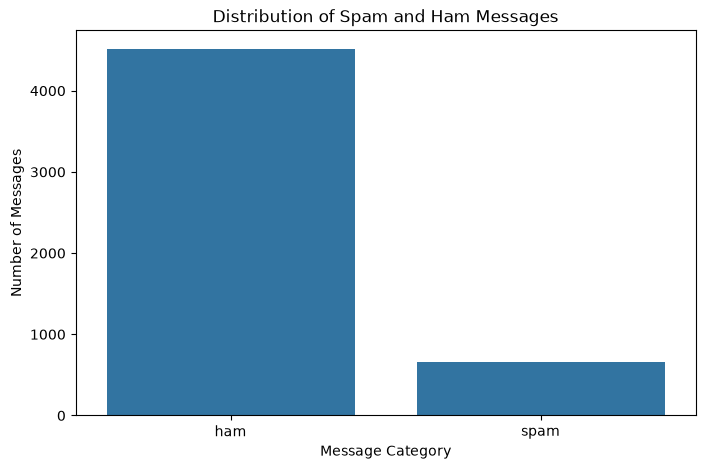

In [10]:
# Count messages in each category
label_counts = df['label'].value_counts()

print("Message counts:")
print(label_counts)

# Calculate percentages
print("\nMessage percentages:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label')

plt.title('Distribution of Spam and Ham Messages')
plt.xlabel('Message Category')
plt.ylabel('Number of Messages')
plt.show()

In [11]:
# Examine sample spam messages
print("SAMPLE SPAM MESSAGES:\n")

for message in df[df['label'] == 'spam']['message'].head(5):
    print("-", message)

print("\nSAMPLE HAM MESSAGES:\n")

for message in df[df['label'] == 'ham']['message'].head(5):
    print("-", message)

SAMPLE SPAM MESSAGES:

- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
- SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info

SAMPLE HAM MESSAGES:

- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then

In [12]:
import re
import string

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Create a new column without changing original messages
df['cleaned_message'] = df['message'].apply(clean_text)

# Compare original and cleaned messages
print("Original message:")
print(df['message'].iloc[2])

print("\nCleaned message:")
print(df['cleaned_message'].iloc[2])

Original message:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Cleaned message:
free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s


In [14]:
# Tokenization

df['tokens'] = df['cleaned_message'].apply(lambda x: x.split())

# Compare cleaned text with tokens
print("Cleaned message:")
print(df['cleaned_message'].iloc[2])

print("\nTokenized message:")
print(df['tokens'].iloc[2])

Cleaned message:
free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s

Tokenized message:
['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', '21st', 'may', '2005', 'text', 'fa', 'to', '87121', 'to', 'receive', 'entry', 'questionstd', 'txt', 'ratetcs', 'apply', '08452810075over18s']


In [15]:
# Separate messages (features) and labels (target)

X = df['cleaned_message']
y = df['label']

print("Features (X):")
print(X.head())

print("\nTarget labels (y):")
print(y.head())

print("\nTotal messages:", len(X))
print("Total labels:", len(y))

Features (X):
0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in 2 a wkly comp to win fa cup fina...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: cleaned_message, dtype: str

Target labels (y):
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str

Total messages: 5169
Total labels: 5169


In [16]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training data:", X_train.shape[0])
print("Testing data:", X_test.shape[0])

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data: 4135
Testing data: 1034

Training labels:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing labels:
label
ham     903
spam    131
Name: count, dtype: int64


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer()

# Learn vocabulary and transform training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display results
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

print("\nNumber of unique words/features:", len(tfidf.get_feature_names_out()))

Training data shape: (4135, 8358)
Testing data shape: (1034, 8358)

Number of unique words/features: 8358


In [18]:
from sklearn.naive_bayes import MultinomialNB

# Initialize the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [19]:
# Predict labels for testing data
y_pred = nb_model.predict(X_test_tfidf)

# Compare actual and predicted labels
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(results.head(10))

  Actual Predicted
0    ham       ham
1    ham       ham
2    ham       ham
3    ham       ham
4    ham       ham
5    ham       ham
6    ham       ham
7    ham       ham
8    ham       ham
9    ham       ham


In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 94.87 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       903
        spam       1.00      0.60      0.75       131

    accuracy                           0.95      1034
   macro avg       0.97      0.80      0.86      1034
weighted avg       0.95      0.95      0.94      1034


Confusion Matrix:
[[903   0]
 [ 53  78]]


In [21]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [22]:
# Predict using Logistic Regression
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluate accuracy
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr) * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 96.03 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.96      0.72      0.82       131

    accuracy                           0.96      1034
   macro avg       0.96      0.86      0.90      1034
weighted avg       0.96      0.96      0.96      1034


Confusion Matrix:
[[899   4]
 [ 37  94]]


In [23]:
# Train Logistic Regression with balanced class weights

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_balanced.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_balanced = lr_balanced.predict(X_test_tfidf)

# Evaluate
print("Balanced Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Balanced Logistic Regression Accuracy: 97.1 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       903
        spam       0.87      0.91      0.89       131

    accuracy                           0.97      1034
   macro avg       0.93      0.94      0.94      1034
weighted avg       0.97      0.97      0.97      1034


Confusion Matrix:
[[885  18]
 [ 12 119]]


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Create a complete machine-learning pipeline
balanced_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Set up 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model using training data only
cv_results = cross_validate(
    balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': make_scorer(precision_score, pos_label='spam'),
        'recall': make_scorer(recall_score, pos_label='spam'),
        'f1': make_scorer(f1_score, pos_label='spam')
    }
)

# Display average results
print("5-Fold Cross-Validation Results")
print("--------------------------------")

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} (+/- {scores.std():.4f})")

5-Fold Cross-Validation Results
--------------------------------
Accuracy: 0.9717 (+/- 0.0020)
Precision: 0.8685 (+/- 0.0185)
Recall: 0.9156 (+/- 0.0320)
F1: 0.8908 (+/- 0.0094)


In [25]:
from sklearn.model_selection import train_test_split

# Use the original cleaned text messages
final_X = df['cleaned_message']
final_y = df['label']

# Split the data into training and testing sets
final_X_train, final_X_test, final_y_train, final_y_test = train_test_split(
    final_X,
    final_y,
    test_size=0.2,
    random_state=42,
    stratify=final_y
)

print("Final Training Samples:", len(final_X_train))
print("Final Testing Samples:", len(final_X_test))

print("\nTraining Distribution:")
print(final_y_train.value_counts())

print("\nTesting Distribution:")
print(final_y_test.value_counts())

Final Training Samples: 4135
Final Testing Samples: 1034

Training Distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing Distribution:
label
ham     903
spam    131
Name: count, dtype: int64


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create a complete TF-IDF and Logistic Regression pipeline
final_model = Pipeline([
    ('tfidf', TfidfVectorizer(
    stop_words='english'
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

print("Final machine learning pipeline created successfully!")

Final machine learning pipeline created successfully!


In [34]:
# Train the pipeline using training data only
final_model.fit(final_X_train, final_y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make predictions on unseen test messages
final_predictions = final_model.predict(final_X_test)

# Calculate accuracy
final_accuracy = accuracy_score(
    final_y_test,
    final_predictions
)

print("FINAL MODEL EVALUATION")
print("======================")

print(f"Accuracy: {final_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    final_y_test,
    final_predictions
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    final_y_test,
    final_predictions
))

FINAL MODEL EVALUATION
Accuracy: 96.71%

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.98      0.98       903
        spam       0.85      0.89      0.87       131

    accuracy                           0.97      1034
   macro avg       0.92      0.94      0.93      1034
weighted avg       0.97      0.97      0.97      1034


Confusion Matrix:
[[883  20]
 [ 14 117]]


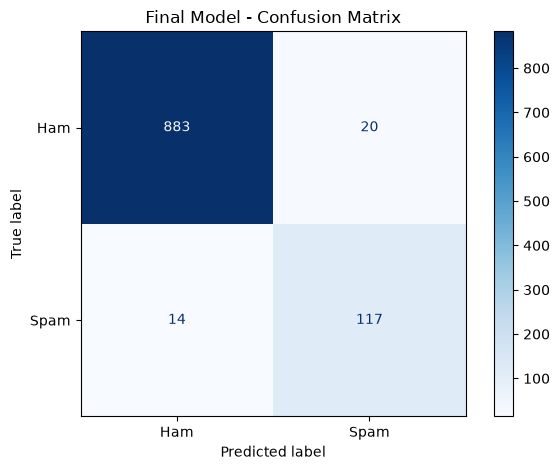

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(
    final_y_test,
    final_predictions,
    labels=['ham', 'spam']
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Final Model - Confusion Matrix')
plt.tight_layout()
plt.show()

In [37]:
# Create new SMS messages for testing
test_messages = [
    "Congratulations! You have won a free iPhone. Claim your prize now!",
    "Hey, are we still meeting tomorrow?",
    "URGENT! You have been selected to receive 1000 dollars. Call now!",
    "Can you please send me the assignment notes?",
    "FREE entry into our weekly cash prize draw. Text WIN now!",
    "I will be home in 20 minutes.",
    "Your account has been selected for a special reward. Click here!",
    "Good morning, hope you have a wonderful day."
]

# Predict message categories
custom_predictions = final_model.predict(test_messages)

# Display results
custom_results = pd.DataFrame({
    'Message': test_messages,
    'Prediction': custom_predictions
})

display(custom_results)

,Message,Prediction
0,Congratulations! You have won a free iPhone. C...,spam
1,"Hey, are we still meeting tomorrow?",ham
2,URGENT! You have been selected to receive 1000...,spam
3,Can you please send me the assignment notes?,ham
4,FREE entry into our weekly cash prize draw. Te...,spam
5,I will be home in 20 minutes.,ham
6,Your account has been selected for a special r...,spam
7,"Good morning, hope you have a wonderful day.",ham


In [38]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs('models', exist_ok=True)

# Save the complete pipeline
joblib.dump(
    final_model,
    'models/spam_detection_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [39]:
# Load the saved model
loaded_model = joblib.load(
    'models/spam_detection_model.pkl'
)

# Test the loaded model
sample_message = [
    "Congratulations! You have won a free cash prize!"
]

prediction = loaded_model.predict(sample_message)

print("Message:", sample_message[0])
print("Prediction:", prediction[0])

Message: Congratulations! You have won a free cash prize!
Prediction: spam


In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    final_model,
    final_X_train,
    final_y_train,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': make_scorer(precision_score, pos_label='spam'),
        'recall': make_scorer(recall_score, pos_label='spam'),
        'f1': make_scorer(f1_score, pos_label='spam')
    }
)

print("5-Fold Cross-Validation Results")
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} (+/- {scores.std():.4f})")

5-Fold Cross-Validation Results
Accuracy: 0.9722 (+/- 0.0063)
Precision: 0.8986 (+/- 0.0297)
Recall: 0.8794 (+/- 0.0221)
F1: 0.8888 (+/- 0.0248)


### Final Model Evaluation and Cross-Validation

The final SMS spam detection model uses a machine learning pipeline combining TF-IDF vectorization with a class-balanced Logistic Regression classifier. Stopword removal is applied during text vectorization.

The model achieved **96.71% accuracy** on the held-out test dataset.

**5-Fold Cross-Validation Results:**

| Metric | Mean Score | Standard Deviation |
|---|---:|---:|
| Accuracy | 97.22% | 0.63% |
| Spam Precision | 89.86% | 2.97% |
| Spam Recall | 87.94% | 2.21% |
| Spam F1-score | 88.88% | 2.48% |

The model achieved 89% spam recall on the test set, correctly identifying 117 out of 131 spam messages. This is particularly important because failing to detect spam can allow unwanted or potentially harmful messages to reach users.

The cross-validation results indicate that the model performs consistently across different training and validation splits.

## Conclusion

In this project, I developed an SMS Spam Detection system using Natural Language Processing and machine learning.

I explored and cleaned the SMS Spam Collection dataset, applied TF-IDF for text feature extraction, and trained multiple classification models, including Multinomial Naive Bayes and Logistic Regression.

After comparing the models, I selected a class-balanced Logistic Regression pipeline as the final model because it provided a strong balance between spam detection and overall classification performance.

The final model achieved **96.71% test accuracy**, with **89% recall for spam messages**. Five-fold cross-validation also produced an average accuracy of 97.22%.

Finally, I tested the model with custom SMS messages and saved it using Joblib so it can be reused for future predictions.

This project helped me understand text preprocessing, feature extraction, classification, model evaluation, and the importance of handling imbalanced datasets.